# Практическая работа № 12
## Кластеризация событий кибербезопасности методом k-means и выявление аномалий

Решение выполнено на `cybersecurity_kmeans_practice_dataset.csv`. Запускайте ячейки сверху вниз: код использует переменные из предыдущих ячеек. Комментарии объясняют основные действия, а выводы помещены в текстовые ячейки.

Модель обучается **без целевой переменной**. `asset_role`, `is_attack` и `attack_type` используются только после обучения и расчёта аномалий для учебной интерпретации. Также не передаются модели идентификаторы, IP-адреса, время и название части набора.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score, calinski_harabasz_score, davies_bouldin_score
)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)

RANDOM_STATE = 42
FEATURES = [
    'connections_per_min', 'unique_destinations', 'failed_logins',
    'outbound_mb', 'session_duration_sec'
]

# CSV лежит рядом с блокнотом, поэтому достаточно имени файла.
# parse_dates превращает текстовое время в дату для итогового просмотра событий.
df = pd.read_csv(
    'cybersecurity_kmeans_practice_dataset.csv',
    parse_dates=['timestamp']
)
display(df.head())

,event_id,timestamp,host_id,source_ip,asset_role,connections_per_min,unique_destinations,failed_logins,outbound_mb,session_duration_sec,dataset_part,is_attack,attack_type
0,EVT-00001,2026-01-01 01:01:00,WEB-063,10.20.13.134,web_server,99.354798,52.217320,3,94.356074,606.785959,train,0,normal
1,EVT-00002,2026-01-01 01:17:00,WS-072,10.20.6.110,workstation,36.983779,5.293541,0,10.825380,325.000453,train,0,normal
2,EVT-00003,2026-01-01 01:52:00,WS-020,10.20.2.24,workstation,23.374431,6.284043,0,0.000000,201.325375,train,0,normal
3,EVT-00004,2026-01-01 02:59:00,WS-033,10.20.18.4,workstation,11.139379,10.217414,0,13.512629,243.175826,train,0,normal
4,EVT-00005,2026-01-01 06:39:00,WEB-048,10.20.7.24,web_server,92.905297,51.327982,3,93.015037,649.583194,train,0,normal


## Задание 1. Аудит и подготовка данных

1. Проверьте размер, пропуски, полные дубликаты и состав частей `train`, `calibration`, `monitoring`.
2. Объясните назначение каждой части.
3. Обучите `StandardScaler` только на `train`, затем тем же объектом преобразуйте `calibration` и `monitoring`.
4. Объясните, почему метки атак и роли узлов нельзя включать в матрицу признаков.

In [2]:
# Проверяем размер и качество данных, как требует задание.
print('Размер таблицы:', df.shape)
print('Пропуски по столбцам:')
display(df.isna().sum().to_frame('Пропусков'))
print('Полных дубликатов:', int(df.duplicated().sum()))
print('Состав частей набора:')
display(df['dataset_part'].value_counts().to_frame('Событий'))

# train — нормальные события для построения профилей;
# calibration — отдельная нормальная выборка для порогов;
# monitoring — новые события, среди которых могут быть атаки.
train_df = df.loc[df['dataset_part'] == 'train'].copy()
calibration_df = df.loc[df['dataset_part'] == 'calibration'].copy()
monitoring_df = df.loc[df['dataset_part'] == 'monitoring'].copy()

# StandardScaler запоминает среднее и стандартное отклонение только train.
# Калибровку и мониторинг переводим в ту же шкалу без повторного fit.
scaler = StandardScaler()
X_train = scaler.fit_transform(train_df[FEATURES])
X_calibration = scaler.transform(calibration_df[FEATURES])
X_monitoring = scaler.transform(monitoring_df[FEATURES])
print('Размеры матриц признаков:', X_train.shape,
      X_calibration.shape, X_monitoring.shape)

Размер таблицы: (1560, 13)
Пропуски по столбцам:


,Пропусков
event_id,0
timestamp,0
host_id,0
source_ip,0
asset_role,0
connections_per_min,0
unique_destinations,0
failed_logins,0
outbound_mb,0
session_duration_sec,0


Полных дубликатов: 0
Состав частей набора:


,Событий
dataset_part,
train,900
monitoring,360
calibration,300


Размеры матриц признаков: (900, 5) (300, 5) (360, 5)


### Вывод по заданию 1

В исходной таблице 1560 событий и 13 столбцов; пропусков и полных дубликатов нет. `train` содержит 900 нормальных событий и нужен для построения кластеров, `calibration` содержит 300 нормальных событий для определения порогов, а `monitoring` содержит 360 новых событий для проверки. `StandardScaler` обучен только на пяти числовых признаках `train`; для двух остальных частей использованы уже найденные средние и стандартные отклонения. Если настроить масштабирование по новым событиям, они изменят эталонную шкалу ещё до проверки. Учебные метки атак и роли узлов не входят в матрицу признаков: их включение заранее сообщило бы модели ответ или заставило бы её группировать события по готовой категории.

## Задание 2. Выбор числа кластеров

Для каждого значения $k$ от 2 до 8 обучите отдельную модель `KMeans` с
`init="k-means++"`, `n_init=20`, `random_state=42`. Рассчитайте:

- Inertia — меньше лучше, но показатель монотонно уменьшается при росте $k$;
- коэффициент силуэта — больше лучше;
- индекс Калински—Харабаша — больше лучше;
- индекс Дэвиса—Болдина — меньше лучше.

Постройте четыре графика средствами `matplotlib`. Определите «локоть» и выберите $k$ по
совокупности графиков и содержательному смыслу профилей.

,Inertia,Силуэт,Калински—Харабаш,Дэвис—Болдин
k,,,,
2,1924.424,0.607,1201.849,0.610
3,210.038,0.826,9160.480,0.259
4,167.456,0.726,7727.310,0.496
5,139.147,0.622,7012.310,0.672
6,113.285,0.501,6923.625,0.804
7,96.046,0.515,6824.390,0.810
8,88.290,0.449,6367.406,0.940


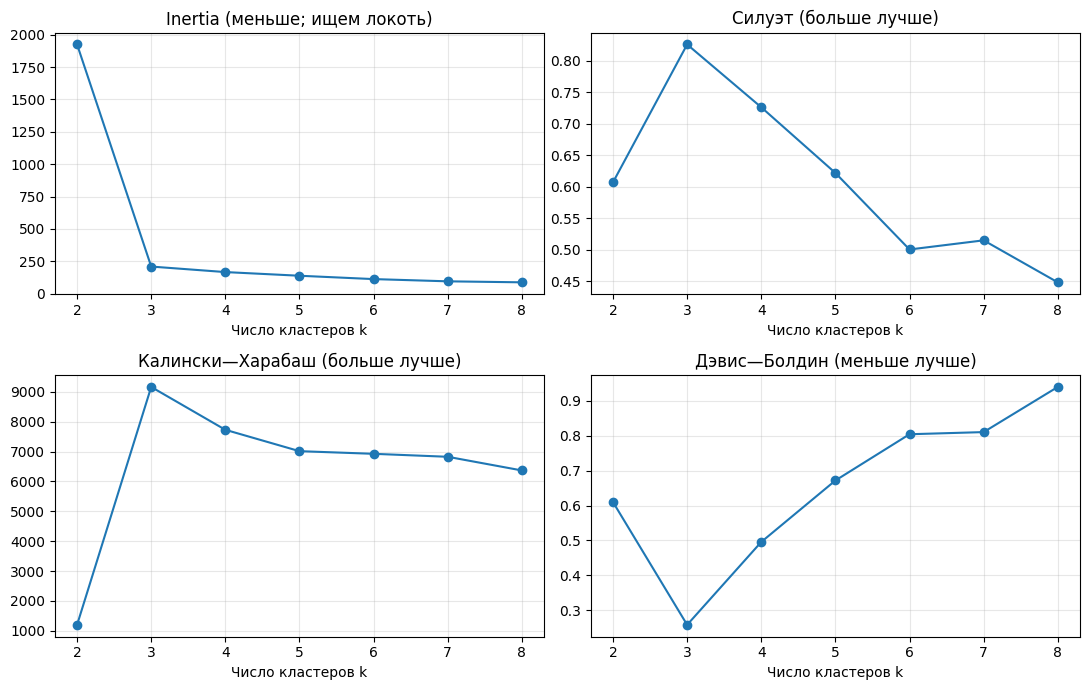

Выбранное число кластеров: 3


In [3]:
# Для каждого k обучаем новую модель с одинаковыми настройками.
# random_state делает результат повторяемым, n_init=20 выбирает
# лучший результат среди двадцати запусков с разными начальными центрами.
metric_rows = []
for k in range(2, 9):
    model = KMeans(
        n_clusters=k, init='k-means++', n_init=20,
        random_state=RANDOM_STATE
    )
    labels = model.fit_predict(X_train)
    metric_rows.append({
        'k': k,
        'Inertia': model.inertia_,
        'Силуэт': silhouette_score(X_train, labels),
        'Калински—Харабаш': calinski_harabasz_score(X_train, labels),
        'Дэвис—Болдин': davies_bouldin_score(X_train, labels)
    })

metrics_df = pd.DataFrame(metric_rows).set_index('k')
display(metrics_df.round(3))

# Четыре метрики показываем на отдельных осях.
# Inertia всегда уменьшается при добавлении кластеров — ищем перегиб,
# а не абсолютный минимум. Остальные метрики сравниваем совместно.
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
plot_info = [
    ('Inertia', axes[0, 0], 'меньше; ищем локоть'),
    ('Силуэт', axes[0, 1], 'больше лучше'),
    ('Калински—Харабаш', axes[1, 0], 'больше лучше'),
    ('Дэвис—Болдин', axes[1, 1], 'меньше лучше')
]
for column, ax, hint in plot_info:
    ax.plot(metrics_df.index, metrics_df[column], marker='o')
    ax.set_title(column + ' (' + hint + ')')
    ax.set_xlabel('Число кластеров k')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Окончательный выбор обосновывается таблицей, графиками и профилями узлов.
chosen_k = 3
print('Выбранное число кластеров:', chosen_k)

### Вывод по заданию 2

Для `k=3` значение Inertia резко падает с 1924,424 до 210,038, после чего уменьшение становится гораздо слабее: это «локоть». Коэффициент силуэта при `k=3` максимален (0,826), индекс Калински—Харабаша также максимален (9160,480), а индекс Дэвиса—Болдина минимален (0,259) среди проверенных вариантов. Три кластера имеют понятный смысл для трёх основных режимов нормальной активности узлов. Поэтому выбрано `k=3`, хотя Inertia сама по себе продолжает уменьшаться при росте числа кластеров. Все четыре графика построены по одним и тем же 900 обучающим событиям и настройкам модели.

## Задание 3. k-means, k-means++ и интерпретация центроидов

1. Обучите две модели при выбранном $k$: с `init="random"` и `init="k-means++"`.
2. Сопоставьте `inertia_` и `n_iter_`. Объясните роль `n_init` и `random_state`.
3. Переведите центроиды k-means++ в исходные единицы методом `inverse_transform`.
4. Сопоставьте кластеры с контрольным полем `asset_role` только после обучения.
5. Постройте две проекции кластеров и центроидов. Помните, что модель использует все пять признаков.

,Инициализация,Inertia,Итераций
0,random,210.038,3
1,k-means++,210.038,2


,connections_per_min,unique_destinations,failed_logins,outbound_mb,session_duration_sec
Кластер,,,,,
0,50.04,15.09,0.21,450.23,1797.07
1,99.05,50.07,3.02,79.55,599.48
2,25.00,10.18,0.51,9.98,171.97


Роль узла по кластерам:


asset_role,backup_server,web_server,workstation
cluster,,,
0,300,0,0
1,0,300,0
2,0,0,300


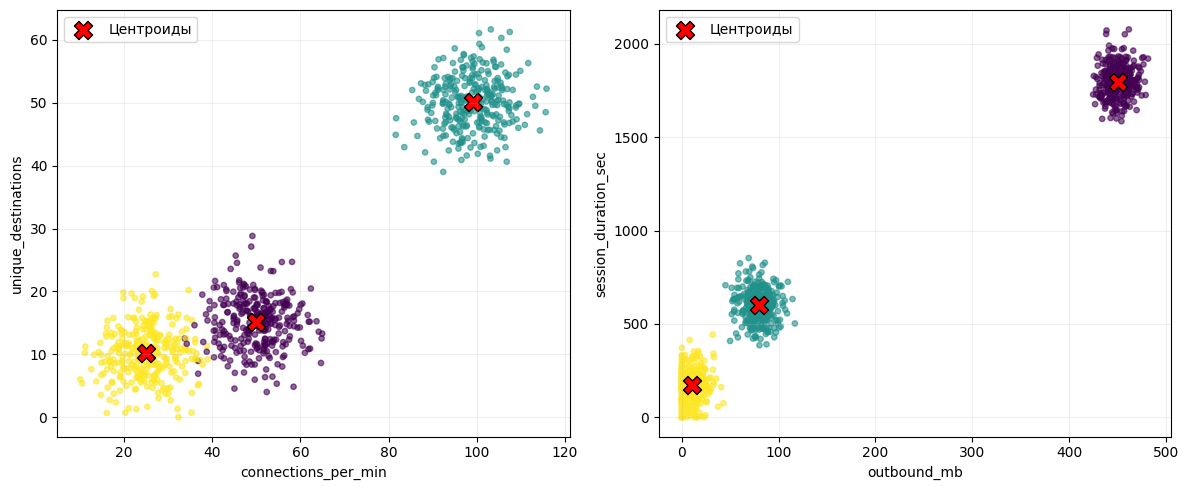

In [4]:
# Сравниваем два способа начальной расстановки центров.
# Остальные параметры одинаковы, поэтому сравнение относится к init.
kmeans_random = KMeans(
    n_clusters=chosen_k, init='random', n_init=20,
    random_state=RANDOM_STATE
)
kmeans_plus = KMeans(
    n_clusters=chosen_k, init='k-means++', n_init=20,
    random_state=RANDOM_STATE
)
kmeans_random.fit(X_train)
train_clusters = kmeans_plus.fit_predict(X_train)

comparison = pd.DataFrame({
    'Инициализация': ['random', 'k-means++'],
    'Inertia': [kmeans_random.inertia_, kmeans_plus.inertia_],
    'Итераций': [kmeans_random.n_iter_, kmeans_plus.n_iter_]
})
display(comparison.round(3))

# Центры хранятся в стандартизованной шкале.
# inverse_transform возвращает понятные исходные единицы признаков.
centers_original = scaler.inverse_transform(kmeans_plus.cluster_centers_)
centroids_df = pd.DataFrame(centers_original, columns=FEATURES)
centroids_df.index.name = 'Кластер'
display(centroids_df.round(2))

# Только после обучения сопоставляем номера кластеров с учебными ролями.
train_result = train_df.copy()
train_result['cluster'] = train_clusters
print('Роль узла по кластерам:')
display(pd.crosstab(train_result['cluster'], train_result['asset_role']))

# Модель использовала пять признаков; на графиках показываем две проекции.
# Поэтому близость точек на рисунке не равна близости во всём пространстве.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
projections = [
    ('connections_per_min', 'unique_destinations'),
    ('outbound_mb', 'session_duration_sec')
]
for ax, (x_feature, y_feature) in zip(axes, projections):
    ax.scatter(train_result[x_feature], train_result[y_feature],
               c=train_clusters, cmap='viridis', s=15, alpha=0.6)
    ax.scatter(centroids_df[x_feature], centroids_df[y_feature],
               marker='X', s=170, color='red', edgecolor='black',
               label='Центроиды')
    ax.set_xlabel(x_feature)
    ax.set_ylabel(y_feature)
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Вывод по заданию 3

При `k=3` обе инициализации дали одинаковую Inertia 210,038, но лучший запуск `k-means++` завершился за 2 итерации, а `random` — за 3. `n_init=20` выбирает лучший результат из двадцати запусков, а `random_state=42` делает эксперимент воспроизводимым; по одному набору данных нельзя утверждать, что одна инициализация всегда лучше. После обратного преобразования центров кластер 0 соответствует резервным серверам (в среднем 450,23 Мбайт исходящего трафика и сессия 1797,07 с), кластер 1 — веб‑серверам (99,05 соединения и 50,07 назначения в минуту), кластер 2 — рабочим станциям (25,00 соединений и 9,98 Мбайт). Сопоставление с `asset_role` после обучения показало ровно по 300 событий нужной роли в каждом кластере. Две двумерные проекции помогают увидеть группы, но решение модели основано на всех пяти числовых признаках.

## Задание 4. Выявление аномалий в двух режимах

Оценка аномальности объекта — расстояние до назначенного центроида:

$$A(x_i)=\lVert x_i-\mu_{c_i}\rVert_2.$$

Для каждого кластера используйте порог 99-го процентиля.

**Режим А — ретроспективный анализ всей выборки.** Масштабируйте всю выборку, обучите k-means
на ней, вычислите расстояния методом `transform` и отметьте наиболее удалённые объекты.

**Режим Б — новые объекты.** Не переобучайте модель. Получите пороги на нормальной
`calibration`, затем методами `predict` и `transform` оцените `monitoring`. Сопоставьте результат
с `is_attack` только после получения прогнозов.

In [5]:
# Режим А: ретроспективно строим новые кластеры на ВСЕХ данных.
# Это отдельный эксперимент: здесь даже будущие события влияют на центры.
scaler_all = StandardScaler()
X_all = scaler_all.fit_transform(df[FEATURES])
kmeans_all = KMeans(
    n_clusters=chosen_k, init='k-means++', n_init=20,
    random_state=RANDOM_STATE
)
all_clusters = kmeans_all.fit_predict(X_all)
all_distances = kmeans_all.transform(X_all)

# У каждой точки берём расстояние до назначенного, а не любого центроида.
all_scores = all_distances[np.arange(len(df)), all_clusters]
retro_result = df[['event_id', 'timestamp', 'host_id', *FEATURES]].copy()
retro_result['cluster'] = all_clusters
retro_result['score'] = all_scores

# В разных кластерах разброс различается: порог 99% свой для каждого.
retro_thresholds = retro_result.groupby('cluster')['score'].quantile(0.99)
retro_result['threshold'] = retro_result['cluster'].map(retro_thresholds)
retro_result['anomaly'] = retro_result['score'] > retro_result['threshold']
print('Ретроспективные пороги:')
display(retro_thresholds.round(3).to_frame('Порог 99%'))
print('Ретроспективных кандидатов:', int(retro_result['anomaly'].sum()))
print('Самые удалённые события:')
display(retro_result.sort_values('score', ascending=False,
                                 kind='stable').head(10))

# Учебную метку подключаем только после получения ретроспективных флагов.
retro_result['attack_type'] = df['attack_type'].to_numpy()
print('Ретроспективные срабатывания по сценариям:')
display(pd.crosstab(retro_result['attack_type'], retro_result['anomaly']))

# Режим Б: используем уже обученные на train scaler и kmeans_plus.
# Сначала назначаем кластеры и считаем расстояния НОРМАЛЬНОЙ calibration.
calibration_clusters = kmeans_plus.predict(X_calibration)
calibration_distances = kmeans_plus.transform(X_calibration)
calibration_scores = calibration_distances[
    np.arange(len(calibration_df)), calibration_clusters
]
calibration_result = pd.DataFrame({
    'cluster': calibration_clusters, 'score': calibration_scores
})
normal_thresholds = calibration_result.groupby('cluster')['score'].quantile(0.99)
print('Пороги по нормальной calibration:')
display(normal_thresholds.round(3).to_frame('Порог 99%'))

# Новые события оцениваем без fit: центры и масштаб остаются прежними.
monitoring_clusters = kmeans_plus.predict(X_monitoring)
monitoring_distances = kmeans_plus.transform(X_monitoring)
monitoring_scores = monitoring_distances[
    np.arange(len(monitoring_df)), monitoring_clusters
]
monitoring_result = monitoring_df[[
    'event_id', 'timestamp', 'host_id', 'source_ip', *FEATURES
]].copy()
monitoring_result['cluster'] = monitoring_clusters
monitoring_result['score'] = monitoring_scores
monitoring_result['threshold'] = monitoring_result['cluster'].map(
    normal_thresholds
)
monitoring_result['anomaly'] = (
    monitoring_result['score'] > monitoring_result['threshold']
)

# Метки атаки подключаем только после расчёта предсказаний.
monitoring_result['is_attack'] = monitoring_df['is_attack'].to_numpy()
monitoring_result['attack_type'] = monitoring_df['attack_type'].to_numpy()
print('Тревог в monitoring:', int(monitoring_result['anomaly'].sum()))
print('Проверка по атакующим и нормальным событиям:')
display(pd.crosstab(monitoring_result['is_attack'],
                    monitoring_result['anomaly']))
print('Обнаружение по сценариям:')
display(pd.crosstab(monitoring_result['attack_type'],
                    monitoring_result['anomaly']))

Ретроспективные пороги:


,Порог 99%
cluster,
0,9.221
1,4.518
2,0.486


Ретроспективных кандидатов: 17
Самые удалённые события:


,event_id,timestamp,host_id,connections_per_min,unique_destinations,failed_logins,outbound_mb,session_duration_sec,cluster,score,threshold,anomaly
1332,EVT-01333,2026-02-13 15:20:00,WEB-045,154.515129,1.394094,66,4.719730,311.612504,0,10.123315,9.221195,True
1318,EVT-01319,2026-02-13 07:05:00,WEB-075,148.977910,6.174954,64,4.012835,565.350132,0,9.752079,9.221195,True
1456,EVT-01457,2026-02-16 17:50:00,WEB-074,128.372296,6.784684,64,3.950243,345.502014,0,9.711939,9.221195,True
1490,EVT-01491,2026-02-17 12:04:00,WEB-018,134.193653,11.701527,63,3.788720,502.663418,0,9.524605,9.221195,True
1217,EVT-01218,2026-02-10 15:43:00,WEB-019,135.083814,3.553489,62,4.985800,445.781473,0,9.428260,9.221195,True
1558,EVT-01559,2026-02-19 22:50:00,WEB-076,116.426447,11.980324,62,4.489969,637.325514,0,9.342980,9.221195,True
1526,EVT-01527,2026-02-18 21:28:00,WEB-069,129.129069,13.388284,60,4.179554,523.965870,0,9.030711,9.221195,False
1290,EVT-01291,2026-02-12 14:25:00,WS-016,293.591833,252.334085,0,2.395357,94.122893,0,9.007555,9.221195,False
1436,EVT-01437,2026-02-16 02:21:00,WEB-016,99.612013,8.732181,59,5.513096,421.259561,0,8.892867,9.221195,False
1477,EVT-01478,2026-02-17 06:12:00,WEB-008,69.965443,3.411842,55,4.868204,563.320043,0,8.354452,9.221195,False


Ретроспективные срабатывания по сценариям:


anomaly,False,True
attack_type,,
brute_force,14,6
exfiltration,14,6
normal,1495,5
port_scan,20,0


... (2 outputs left out)

Тревог в monitoring: 66
Проверка по атакующим и нормальным событиям:


anomaly,False,True
is_attack,,
0,294,6
1,0,60


Обнаружение по сценариям:


anomaly,False,True
attack_type,,
brute_force,0,20
exfiltration,0,20
normal,294,6
port_scan,0,20


### Вывод по заданию 4

В ретроспективном режиме все 1560 событий влияли на масштаб, центроиды и пороги; при кластерных порогах 99-го процентиля отмечено 17 кандидатов: 6 `brute_force`, 6 `exfiltration` и 5 нормальных событий. Ни одно из 20 событий `port_scan` в этом режиме не отмечено: группа атак может сдвинуть центроид или образовать плотный собственный профиль, и расстояние до назначенного центра перестаёт быть большим. В режиме новых объектов `k-means++` и scaler не переобучались, а пороги по кластерам 0, 1 и 2 получены только из нормальной `calibration`: 0,770, 0,884 и 0,772. На 360 событиях `monitoring` получено 66 тревог: все 60 размеченных атак найдены, 6 нормальных событий отмечены ошибочно и 294 нормальных события оставлены без тревоги. Все три сценария — `brute_force`, `exfiltration` и `port_scan` — обнаружены полностью, по 20 событий каждый. Результаты двух режимов нельзя прямо сравнивать как качество одной неизменной модели, потому что они используют разные обучающие данные, центры и пороги.

## Задание 5. Визуализация и записка SOC

1. Постройте распределение оценок `monitoring` для нормы и атак с помощью `matplotlib`.
2. Отметьте кандидатов на аномалии на одной двумерной проекции.
3. Составьте записку SOC из 5–7 предложений: объём и части данных, выбранное $k$, способ
инициализации, правило порога, число срабатываний, приоритетные события и ограничения.

Ключевое ограничение: большое расстояние означает нетипичность относительно найденного профиля,
но не доказывает атаку.

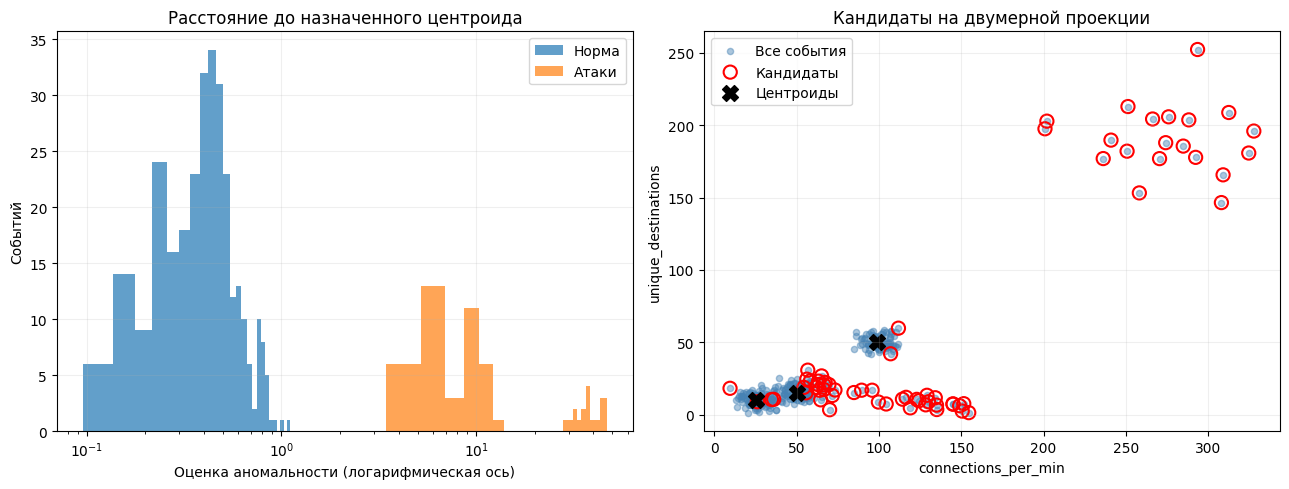

Приоритетные события по расстоянию:


,event_id,timestamp,host_id,source_ip,connections_per_min,unique_destinations,failed_logins,outbound_mb,session_duration_sec,cluster,score,threshold,anomaly,is_attack,attack_type
1332,EVT-01333,2026-02-13 15:20:00,WEB-045,10.20.10.245,154.515129,1.394094,66,4.719730,311.612504,1,46.850584,0.884367,True,1,brute_force
1318,EVT-01319,2026-02-13 07:05:00,WEB-075,10.20.9.25,148.977910,6.174954,64,4.012835,565.350132,1,45.347003,0.884367,True,1,brute_force
1456,EVT-01457,2026-02-16 17:50:00,WEB-074,10.20.11.104,128.372296,6.784684,64,3.950243,345.502014,1,45.328342,0.884367,True,1,brute_force
1490,EVT-01491,2026-02-17 12:04:00,WEB-018,10.20.11.8,134.193653,11.701527,63,3.788720,502.663418,1,44.576948,0.884367,True,1,brute_force
1217,EVT-01218,2026-02-10 15:43:00,WEB-019,10.20.10.31,135.083814,3.553489,62,4.985800,445.781473,1,43.860724,0.884367,True,1,brute_force
1558,EVT-01559,2026-02-19 22:50:00,WEB-076,10.20.11.88,116.426447,11.980324,62,4.489969,637.325514,1,43.824162,0.884367,True,1,brute_force
1526,EVT-01527,2026-02-18 21:28:00,WEB-069,10.20.5.2,129.129069,13.388284,60,4.179554,523.965870,1,42.345527,0.884367,True,1,brute_force
1436,EVT-01437,2026-02-16 02:21:00,WEB-016,10.20.18.93,99.612013,8.732181,59,5.513096,421.259561,1,41.607164,0.884367,True,1,brute_force
1477,EVT-01478,2026-02-17 06:12:00,WEB-008,10.20.18.59,69.965443,3.411842,55,4.868204,563.320043,1,38.672301,0.884367,True,1,brute_force
1338,EVT-01339,2026-02-13 19:48:00,WEB-009,10.20.5.228,144.958845,7.200232,54,5.658635,416.811305,1,37.936447,0.884367,True,1,brute_force


In [6]:
# Оценки нормы и атак показываем разными цветами.
# Значения могут сильно различаться, поэтому по оси X применяем log-шкалу.
normal_mask = monitoring_result['is_attack'] == 0
attack_mask = monitoring_result['is_attack'] == 1
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(monitoring_result.loc[normal_mask, 'score'], bins=25,
             alpha=0.7, label='Норма')
axes[0].hist(monitoring_result.loc[attack_mask, 'score'], bins=25,
             alpha=0.7, label='Атаки')
axes[0].set_xscale('log')
axes[0].set_title('Расстояние до назначенного центроида')
axes[0].set_xlabel('Оценка аномальности (логарифмическая ось)')
axes[0].set_ylabel('Событий')
axes[0].legend()
axes[0].grid(alpha=0.2)

# На проекции выделяем кандидатов по кластерным порогам.
# Кресты — центры нормальных кластеров в исходных единицах.
axes[1].scatter(monitoring_result['connections_per_min'],
                monitoring_result['unique_destinations'],
                c='steelblue', s=20, alpha=0.45, label='Все события')
axes[1].scatter(monitoring_result.loc[monitoring_result['anomaly'],
                                      'connections_per_min'],
                monitoring_result.loc[monitoring_result['anomaly'],
                                      'unique_destinations'],
                facecolors='none', edgecolors='red', s=90,
                linewidth=1.5, label='Кандидаты')
axes[1].scatter(centroids_df['connections_per_min'],
                centroids_df['unique_destinations'], marker='X',
                color='black', s=130, label='Центроиды')
axes[1].set_xlabel('connections_per_min')
axes[1].set_ylabel('unique_destinations')
axes[1].set_title('Кандидаты на двумерной проекции')
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

print('Приоритетные события по расстоянию:')
display(monitoring_result.sort_values('score', ascending=False,
                                      kind='stable').head(10))

### Записка SOC

В наборе 1560 событий: 900 нормальных для обучения, 300 нормальных для настройки порогов и 360 новых для проверки, среди которых размечены 60 атак. По четырём метрикам выбран `k=3`; модель `k-means++` с `n_init=20` и `random_state=42` выделила профили резервных серверов, веб‑серверов и рабочих станций. Для новых событий применены отдельные пороги 99-го процентиля расстояний нормальной калибровки по кластерам 0, 1 и 2: 0,770, 0,884 и 0,772. На мониторинге отмечено 66 событий, в том числе все 60 размеченных атак и 6 нормальных событий; без тревоги остались 294 нормальных события. В ретроспективном режиме кластеризация всей выборки дала лишь 17 кандидатов: 12 атак и 5 нормальных событий, причём все 20 событий `port_scan` остались без тревоги, что показывает влияние атак на центры и пороги. В первую очередь следует проверить `EVT-01333` на хосте `WEB-045` с 66 неудачными входами и расстоянием 46,85 при пороге 0,884, сопоставив его с журналами аутентификации и сетевыми действиями. Большое расстояние указывает на отличие от нормального профиля, но не доказывает атаку; модель предполагает компактные кластеры, зависит от состава обучающих данных и требует пересмотра при изменении поведения инфраструктуры.